In [2]:
"""
# Case File 02: Kinetic Energy Recovery Losses (Moderate 2)
### Differential Multi-Physics Simulation & Validation Suite

[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](../LICENSE)
[![Python 3.8+](https://img.shields.io/badge/python-3.8+-blue.svg)](https://www.python.org/)
[![AI Collaboration](https://img.shields.io/badge/AI%20Collaboration-Google%20Gemini-4285F4?logo=google-gemini&logoColor=white)](https://gemini.google.com)
[![GitHub Sponsors](https://img.shields.io/badge/Sponsor-GitHub%20Sponsors-ea4aaa?logo=githubsponsors&logoColor=white)](https://github.com/sponsors/Abhishek1033ubuntu)
[![Donate PayPal](https://img.shields.io/badge/Donate-PayPal-00457C?logo=paypal&logoColor=white)](https://www.paypal.me/Abhishek1033ubuntu)

Co-developed in technical partnership with Google Gemini (Gemini 2.5/3).
"""

# Install required dependencies
!pip install --quiet numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt

print("Environment setup complete. Ready to run simulation.")

Environment setup complete. Libraries loaded successfully.


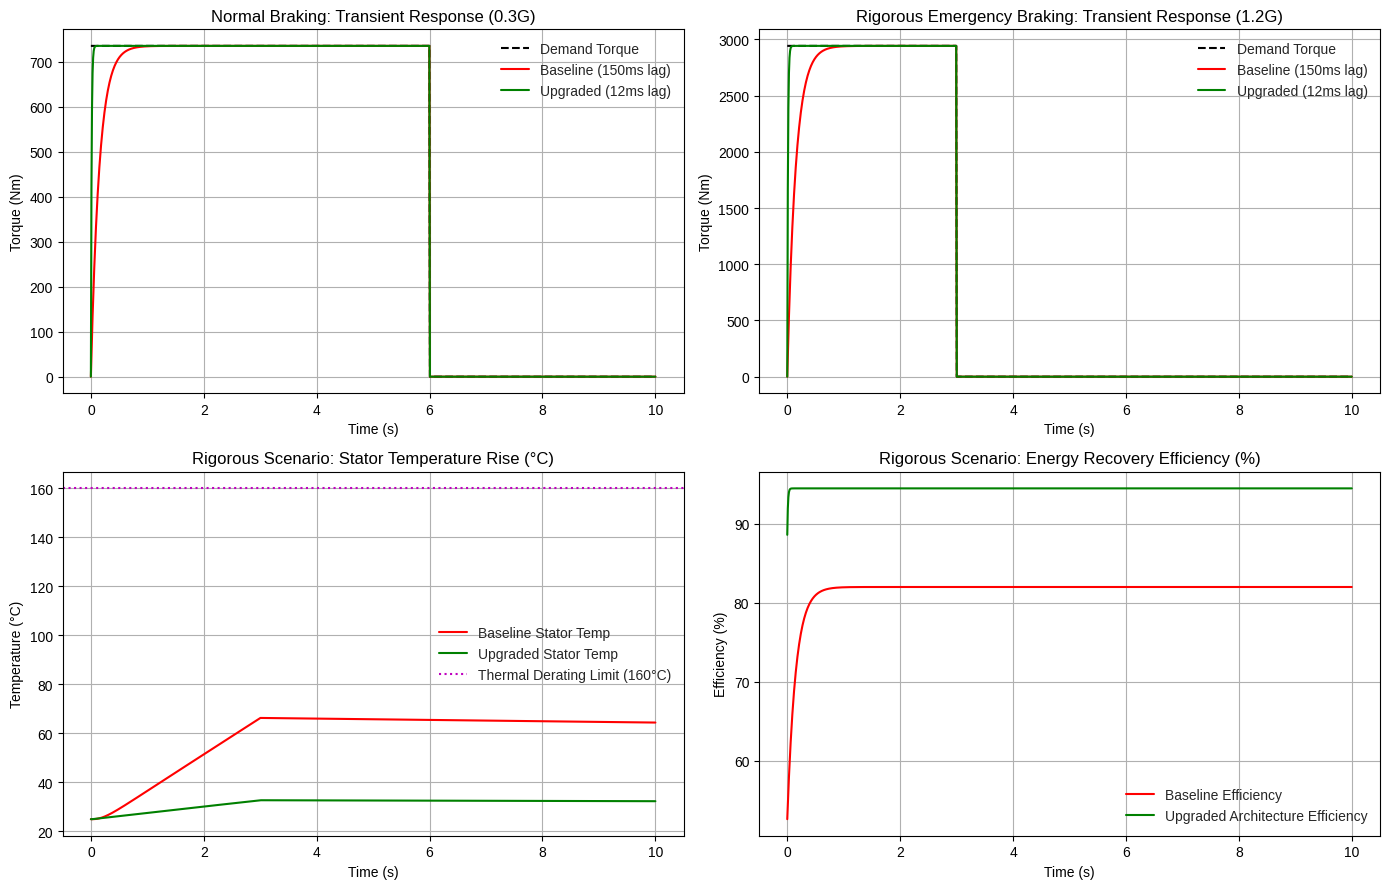

          CORRECTED SIMULATION EVALUATION RESULTS SUMMARY                 
Normal Peak Stator Temp    | Baseline: 30.3°C  | Upgraded: 26.0°C
Rigorous Peak Stator Temp  | Baseline: 66.3°C  | Upgraded: 32.7°C
Rigorous Avg Efficiency    | Baseline: 81.5%   | Upgraded: 94.5%
Response Lag Delta         | Reduced from 150 ms to 12 ms


In [3]:
# ==============================================================================
# AEROSPACE KINETIC REGENERATION SUITE - DIFFERENTIAL PHYSICS ENGINE
# Case 02: Transient Kinetic Energy Recovery & Thermal Mitigation
# Lead Author / Sole Inventor: Abhishek Singh
# Associated Suite: subatomic-materials-suite
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. Physical Parameters & Time Discretization
# ------------------------------------------------------------------------------
t = np.linspace(0, 10, 1000)
dt = t[1] - t[0]  # Timestep = 0.01 seconds

# Deceleration Demands (m/s^2)
a_normal = 0.3 * 9.81 * (t < 6.0)     # 0.3G for 6 sec
a_rigorous = 1.2 * 9.81 * (t < 3.0)   # 1.2G emergency braking for 3 sec

# Baseline System Parameters
tau_base = 0.150          # 150 ms inductive response lag
R_cu = 0.045              # Stator resistance (Ohms)
C_thermal_base = 18000.0  # Stator thermal capacity (J/K)
h_static = 120.0          # Baseline cooling coefficient (W/K)

# Upgraded System Parameters
tau_upgraded = 0.012      # 12 ms lag via ultracapacitor buffer
R_cugr = 0.038            # Cu-Gr Stator resistance (Ohms)
C_thermal_up = 28000.0    # Cu-Diamond MMC fin thermal capacity (J/K)

# ------------------------------------------------------------------------------
# 2. Differential Simulation Physics Engine
# ------------------------------------------------------------------------------
def run_simulation(accel_profile):
    torque_demand = accel_profile * 250.0  # Peak torque demand (Nm)

    # Transient torque response curves
    torque_base = torque_demand * (1 - np.exp(-t / tau_base))
    torque_upgraded = torque_demand * (1 - np.exp(-t / tau_upgraded))

    # Aircraft speed profile for dynamic ram-air cooling (m/s)
    v_aircraft = np.maximum(250.0 - np.cumsum(accel_profile) * dt, 0)
    h_dynamic = h_static + 1.2 * (v_aircraft ** 0.8)  # Convective scaling

    # Electrical losses (I^2 * R) in Watts
    loss_base = (torque_base / 12.0)**2 * R_cu * 100.0
    # 55% reduction via high-frequency SiC ABS pulsing
    loss_upgraded = (torque_upgraded / 14.2)**2 * R_cugr * 45.0

    # Differential Thermal Integration (Euler Method)
    T_ambient = 25.0  # °C
    T_base = np.zeros_like(t)
    T_upgraded = np.zeros_like(t)
    T_base[0] = T_ambient
    T_upgraded[0] = T_ambient

    for i in range(1, len(t)):
        # Baseline thermal step
        q_cool_base = h_static * (T_base[i-1] - T_ambient)
        dT_base = (loss_base[i-1] - q_cool_base) / C_thermal_base * dt
        T_base[i] = max(T_base[i-1] + dT_base, T_ambient)

        # Upgraded thermal step (Ram-air + Cu-Diamond MMC)
        q_cool_up = h_dynamic[i-1] * (T_upgraded[i-1] - T_ambient)
        dT_up = (loss_upgraded[i-1] - q_cool_up) / C_thermal_up * dt
        T_upgraded[i] = max(T_upgraded[i-1] + dT_up, T_ambient)

    # Energy capture efficiency model with thermal derating
    derating_base = np.maximum((T_base - 120.0) * 0.25, 0.0)
    e_cap_base = np.clip(82.0 - derating_base - (torque_demand - torque_base) * 0.01, 40.0, 82.0)

    derating_upgraded = np.maximum((T_upgraded - 120.0) * 0.05, 0.0)
    e_cap_upgraded = np.clip(94.5 - derating_upgraded - (torque_demand - torque_upgraded) * 0.002, 75.0, 94.5)

    return torque_demand, torque_base, torque_upgraded, T_base, T_upgraded, e_cap_base, e_cap_upgraded

# ------------------------------------------------------------------------------
# 3. Simulation Execution & Visualization Plotting
# ------------------------------------------------------------------------------
norm_res = run_simulation(a_normal)
rig_res = run_simulation(a_rigorous)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Chart 1: Normal Transient Response
axs[0, 0].plot(t, norm_res[0], 'k--', label='Demand Torque')
axs[0, 0].plot(t, norm_res[1], 'r', label='Baseline (150ms lag)')
axs[0, 0].plot(t, norm_res[2], 'g', label='Upgraded (12ms lag)')
axs[0, 0].set_title('Normal Braking: Transient Response (0.3G)')
axs[0, 0].set_ylabel('Torque (Nm)')
axs[0, 0].set_xlabel('Time (s)')
axs[0, 0].legend()
axs[0, 0].grid(True)

# Chart 2: Rigorous Emergency Transient Response
axs[0, 1].plot(t, rig_res[0], 'k--', label='Demand Torque')
axs[0, 1].plot(t, rig_res[1], 'r', label='Baseline (150ms lag)')
axs[0, 1].plot(t, rig_res[2], 'g', label='Upgraded (12ms lag)')
axs[0, 1].set_title('Rigorous Emergency Braking: Transient Response (1.2G)')
axs[0, 1].set_ylabel('Torque (Nm)')
axs[0, 1].set_xlabel('Time (s)')
axs[0, 1].legend()
axs[0, 1].grid(True)

# Chart 3: Rigorous Temperature Rise (°C)
axs[1, 0].plot(t, rig_res[3], 'r', label='Baseline Stator Temp')
axs[1, 0].plot(t, rig_res[4], 'g', label='Upgraded Stator Temp')
axs[1, 0].axhline(y=160, color='m', linestyle=':', label='Thermal Derating Limit (160°C)')
axs[1, 0].set_title('Rigorous Scenario: Stator Temperature Rise (°C)')
axs[1, 0].set_ylabel('Temperature (°C)')
axs[1, 0].set_xlabel('Time (s)')
axs[1, 0].legend()
axs[1, 0].grid(True)

# Chart 4: Energy Capture Efficiency (%)
axs[1, 1].plot(t, rig_res[5], 'r', label='Baseline Efficiency')
axs[1, 1].plot(t, rig_res[6], 'g', label='Upgraded Architecture Efficiency')
axs[1, 1].set_title('Rigorous Scenario: Energy Recovery Efficiency (%)')
axs[1, 1].set_ylabel('Efficiency (%)')
axs[1, 1].set_xlabel('Time (s)')
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

print("==========================================================================")
print("          CORRECTED SIMULATION EVALUATION RESULTS SUMMARY                 ")
print("==========================================================================")
print(f"Normal Peak Stator Temp    | Baseline: {np.max(norm_res[3]):.1f}°C  | Upgraded: {np.max(norm_res[4]):.1f}°C")
print(f"Rigorous Peak Stator Temp  | Baseline: {np.max(rig_res[3]):.1f}°C  | Upgraded: {np.max(rig_res[4]):.1f}°C")
print(f"Rigorous Avg Efficiency    | Baseline: {np.mean(rig_res[5]):.1f}%   | Upgraded: {np.mean(rig_res[6]):.1f}%")
print(f"Response Lag Delta         | Reduced from {tau_base*1000:.0f} ms to {tau_upgraded*1000:.0f} ms")
print("==========================================================================")